In [ ]:
from pathlib import Path

data_dir = Path("/Users/aficca/Documents/stor566_proj/archive_clean")

train_dir = data_dir / "train"
val_dir = data_dir / "validation"
test_dir = data_dir / "test"

print(train_dir)
print(val_dir)
print(test_dir)

/Users/aficca/Documents/stor566_proj/archive/train
/Users/aficca/Documents/stor566_proj/archive/test


In [ ]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(train_dir)
val_dataset = ImageFolder(val_dir)
test_dataset = ImageFolder(test_dir)

print("Training images:", len(train_dataset))
print("Validation images: ", len(val_dataset))
print("Test images:", len(test_dataset))

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

Training images: 28709
Test images: 7178
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Class mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


In [34]:
image, label = train_dataset[0]

print("Image size:", image.size)
print("Image mode:", image.mode)
print("Example label:", train_dataset.classes[label])

Image size: (48, 48)
Image mode: RGB
Example label: angry


In [56]:
%whos

Variable              Type                  Data/Info
-----------------------------------------------------
DataLoader            type                  <class 'torch.utils.data.dataloader.DataLoader'>
Dataset               type                  <class 'torch.utils.data.dataset.Dataset'>
FER_CNN               type                  <class '__main__.FER_CNN'>
ImageFolder           type                  <class 'torchvision.datasets.folder.ImageFolder'>
Path                  type                  <class 'pathlib.Path'>
TransformedDataset    type                  <class '__main__.TransformedDataset'>
accuracy_score        function              <function accuracy_score at 0x36023b1a0>
all_labels            ndarray               7178: 7178 elems, type `int64`, 57424 bytes
all_predictions       ndarray               7178: 7178 elems, type `int64`, 57424 bytes
batch_size            int                   32
best_val_accuracy     float                 0.542319749216301
class_name            str   

In [57]:
from pathlib import Path
from PIL import Image
import hashlib
from collections import defaultdict

train_dir = Path("/Users/aficca/Documents/stor566_proj/archive/train")
test_dir = Path("/Users/aficca/Documents/stor566_proj/archive/test")

def image_hash(path):
    with Image.open(path) as img:
        # FER images are grayscale, so convert consistently
        img = img.convert("L")
        return hashlib.md5(img.tobytes()).hexdigest()

# Collect every image
all_images = []

for split, directory in [("train", train_dir), ("test", test_dir)]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            for path in class_dir.glob("*"):
                if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                    all_images.append({
                        "path": path,
                        "split": split,
                        "label": class_dir.name
                    })

print("Total images:", len(all_images))

# Hash images
hash_groups = defaultdict(list)

for item in all_images:
    h = image_hash(item["path"])
    hash_groups[h].append(item)

# Find duplicates
duplicate_groups = {
    h: items for h, items in hash_groups.items()
    if len(items) > 1
}

print("Unique images:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Images involved in duplicates:",
      sum(len(x) for x in duplicate_groups.values()))

Total images: 35887
Unique images: 34034
Duplicate groups: 1516
Images involved in duplicates: 3369


In [58]:
conflicting_groups = {}

for h, items in duplicate_groups.items():
    labels = set(item["label"] for item in items)
    
    if len(labels) > 1:
        conflicting_groups[h] = items

print("Duplicate groups with conflicting labels:",
      len(conflicting_groups))

print("Images involved in conflicting duplicates:",
      sum(len(x) for x in conflicting_groups.values()))

Duplicate groups with conflicting labels: 57
Images involved in conflicting duplicates: 160


In [59]:
within_train = 0
within_test = 0
cross_split = 0

for h, items in duplicate_groups.items():
    splits = set(item["split"] for item in items)

    if splits == {"train"}:
        within_train += 1
    elif splits == {"test"}:
        within_test += 1
    else:
        cross_split += 1

print("Duplicate groups within train:", within_train)
print("Duplicate groups within test:", within_test)
print("Duplicate groups across train/test:", cross_split)

Duplicate groups within train: 936
Duplicate groups within test: 49
Duplicate groups across train/test: 531


In [60]:
from pathlib import Path
from PIL import Image
import hashlib
from collections import defaultdict

train_dir = Path("/Users/aficca/Documents/stor566_proj/archive/train")
test_dir = Path("/Users/aficca/Documents/stor566_proj/archive/test")

# --------------------------------------------------
# 1. Collect all images
# --------------------------------------------------

all_images = []

for split, directory in [("train", train_dir), ("test", test_dir)]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            for path in class_dir.iterdir():
                if path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                    all_images.append({
                        "path": path,
                        "split": split,
                        "label": class_dir.name
                    })

print("Original images:", len(all_images))


# --------------------------------------------------
# 2. Hash every image
# --------------------------------------------------

def image_hash(path):
    with Image.open(path) as img:
        img = img.convert("L")
        return hashlib.md5(img.tobytes()).hexdigest()


hash_groups = defaultdict(list)

for item in all_images:
    hash_groups[image_hash(item["path"])].append(item)


# --------------------------------------------------
# 3. Remove ALL conflicting-label duplicate groups
# --------------------------------------------------

conflicting_hashes = set()

for h, items in hash_groups.items():
    labels = {item["label"] for item in items}

    if len(labels) > 1:
        conflicting_hashes.add(h)


print("Conflicting duplicate groups:", len(conflicting_hashes))


# --------------------------------------------------
# 4. Resolve remaining duplicates
#
# Priority:
# train > test
#
# Since validation does not exist yet, we will create
# validation AFTER duplicate cleaning.
# --------------------------------------------------

kept = []

for h, items in hash_groups.items():

    # Remove conflicting-label duplicates entirely
    if h in conflicting_hashes:
        continue

    # All remaining copies have the same label.
    # Prefer train over test.
    train_items = [x for x in items if x["split"] == "train"]
    
    if train_items:
        kept.append(train_items[0])
    else:
        kept.append(items[0])


print("Images after duplicate cleaning:", len(kept))


# --------------------------------------------------
# 5. Count remaining images by original split
# --------------------------------------------------

train_clean = [x for x in kept if x["split"] == "train"]
test_clean = [x for x in kept if x["split"] == "test"]

print("Clean train:", len(train_clean))
print("Clean test:", len(test_clean))
print("Total:", len(train_clean) + len(test_clean))

Original images: 35887
Conflicting duplicate groups: 57
Images after duplicate cleaning: 33977
Clean train: 27418
Clean test: 6559
Total: 33977


In [62]:
print("Train examples:")
for item in train_clean[:5]:
    print(item["path"].name)

print("\nTest examples:")
for item in test_clean[:5]:
    print(item["path"].name)

Train examples:
Training_35668808.jpg
Training_92439792.jpg
Training_78260987.jpg
Training_23736738.jpg
Training_16211575.jpg

Test examples:
PrivateTest_14565821.jpg
PublicTest_65465298.jpg
PublicTest_93558553.jpg
PublicTest_28963544.jpg
PublicTest_90347378.jpg


In [63]:
# Separate the cleaned images according to the original FER-2013 split

final_train = [
    item for item in kept
    if item["path"].name.startswith("Training_")
]

final_val = [
    item for item in kept
    if item["path"].name.startswith("PublicTest_")
]

final_test = [
    item for item in kept
    if item["path"].name.startswith("PrivateTest_")
]

print("Final training:", len(final_train))
print("Final validation:", len(final_val))
print("Final test:", len(final_test))
print("Total:", len(final_train) + len(final_val) + len(final_test))

Final training: 27418
Final validation: 3281
Final test: 3278
Total: 33977


In [64]:
from collections import Counter

three_split_duplicates = Counter()

for h, items in hash_groups.items():
    if len(items) > 1:
        splits = tuple(sorted(set(
            "Training" if x["path"].name.startswith("Training_")
            else "PublicTest" if x["path"].name.startswith("PublicTest_")
            else "PrivateTest"
            for x in items
        )))
        
        three_split_duplicates[splits] += 1

for splits, count in three_split_duplicates.items():
    print(splits, ":", count)

('PrivateTest', 'Training') : 261
('Training',) : 936
('PrivateTest', 'PublicTest', 'Training') : 17
('PublicTest', 'Training') : 253
('PrivateTest', 'PublicTest') : 26
('PublicTest',) : 16
('PrivateTest',) : 7


In [65]:
# Specifically look at duplicates involving PublicTest and PrivateTest
for h, items in hash_groups.items():
    splits = {
        "Training" if x["path"].name.startswith("Training_")
        else "PublicTest" if x["path"].name.startswith("PublicTest_")
        else "PrivateTest"
        for x in items
    }
    
    if "PublicTest" in splits or "PrivateTest" in splits:
        if len(items) > 1:
            print("\n---")
            for x in items:
                print(x["path"].name, "|", x["label"])


---
Training_35668808.jpg | angry
Training_54232828.jpg | angry
Training_76182522.jpg | angry
Training_27131777.jpg | angry
PrivateTest_68156545.jpg | angry
PrivateTest_38456003.jpg | angry
PrivateTest_80645015.jpg | angry

---
Training_40416731.jpg | angry
Training_27263765.jpg | angry
Training_27785233.jpg | angry
Training_52823874.jpg | angry
PrivateTest_59389857.jpg | angry
PublicTest_63906265.jpg | angry
PublicTest_85586711.jpg | angry

---
Training_37752731.jpg | angry
Training_25396368.jpg | angry
Training_67283529.jpg | angry
PrivateTest_92905981.jpg | angry
PublicTest_31362928.jpg | angry

---
Training_78379622.jpg | angry
PublicTest_49302808.jpg | angry

---
Training_75624538.jpg | angry
PublicTest_4822332.jpg | angry

---
Training_36414634.jpg | angry
Training_98000381.jpg | angry
Training_65039115.jpg | angry
Training_33414933.jpg | angry
Training_4309137.jpg | angry
PrivateTest_35759444.jpg | angry
PrivateTest_88815839.jpg | angry

---
Training_98801026.jpg | angry
Traini

In [66]:
# ============================================================
# Correct duplicate resolution using the ORIGINAL 3 FER splits
# Priority: Training > PublicTest > PrivateTest
# ============================================================

def get_original_split(path):
    name = path.name
    
    if name.startswith("Training_"):
        return "Training"
    elif name.startswith("PublicTest_"):
        return "PublicTest"
    elif name.startswith("PrivateTest_"):
        return "PrivateTest"
    else:
        return None


split_priority = {
    "Training": 0,
    "PublicTest": 1,
    "PrivateTest": 2
}

# ------------------------------------------------------------
# Resolve duplicates
# ------------------------------------------------------------

kept_correct = []

for h, items in hash_groups.items():

    # Get labels in this duplicate group
    labels = {item["label"] for item in items}

    # Remove ALL copies if labels conflict
    if len(labels) > 1:
        continue

    # Add original FER split information
    for item in items:
        item["original_split"] = get_original_split(item["path"])

    # Sort according to proposal priority:
    # Training > PublicTest > PrivateTest
    items_sorted = sorted(
        items,
        key=lambda x: split_priority[x["original_split"]]
    )

    # Keep only the highest-priority copy
    kept_correct.append(items_sorted[0])


# ------------------------------------------------------------
# Separate final datasets
# ------------------------------------------------------------

final_train = [
    item for item in kept_correct
    if item["original_split"] == "Training"
]

final_val = [
    item for item in kept_correct
    if item["original_split"] == "PublicTest"
]

final_test = [
    item for item in kept_correct
    if item["original_split"] == "PrivateTest"
]


# ------------------------------------------------------------
# Print final counts
# ------------------------------------------------------------

print("Final training:", len(final_train))
print("Final validation:", len(final_val))
print("Final test:", len(final_test))
print("Total:", len(kept_correct))

Final training: 27418
Final validation: 3291
Final test: 3268
Total: 33977


In [67]:
from pathlib import Path
import shutil

clean_dir = Path("/Users/aficca/Documents/stor566_proj/archive_clean")

classes = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "sad",
    "surprise"
]

# Create directories
for split in ["train", "validation", "test"]:
    for cls in classes:
        (clean_dir / split / cls).mkdir(parents=True, exist_ok=True)

# Copy files into the correct split/class folder
def copy_items(items, split_name):
    for item in items:
        src = item["path"]
        label = item["label"]
        
        dst = clean_dir / split_name / label / src.name
        shutil.copy2(src, dst)

copy_items(final_train, "train")
copy_items(final_val, "validation")
copy_items(final_test, "test")

print("Clean dataset created at:")
print(clean_dir)

Clean dataset created at:
/Users/aficca/Documents/stor566_proj/archive_clean


In [68]:
from torchvision.datasets import ImageFolder

train_raw = ImageFolder(clean_dir / "train")
val_raw = ImageFolder(clean_dir / "validation")
test_raw = ImageFolder(clean_dir / "test")

print("Training:", len(train_raw))
print("Validation:", len(val_raw))
print("Test:", len(test_raw))
print("Classes:", train_raw.classes)

Training: 27418
Validation: 3291
Test: 3268
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [69]:
from pathlib import Path
from torchvision.datasets import ImageFolder

clean_dir = Path("/Users/aficca/Documents/stor566_proj/archive_clean")

train_dir = clean_dir / "train"
val_dir = clean_dir / "validation"
test_dir = clean_dir / "test"

train_raw = ImageFolder(train_dir)
val_raw = ImageFolder(val_dir)
test_raw = ImageFolder(test_dir)

print("Training:", len(train_raw))
print("Validation:", len(val_raw))
print("Test:", len(test_raw))
print("Classes:", train_raw.classes)

Training: 27418
Validation: 3291
Test: 3268
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [71]:
import torch
import torchvision.transforms as transforms

cnn_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

from torchvision.datasets import ImageFolder

cnn_train = ImageFolder(
    train_dir,
    transform=cnn_transform
)
cnn_val = ImageFolder(
    val_dir,
    transform=cnn_transform
)
cnn_test = ImageFolder(
    test_dir,
    transform=cnn_transform
)
print("CNN training:", len(cnn_train))
print("CNN validation:", len(cnn_val))
print("CNN test:", len(cnn_test))

CNN training: 27418
CNN validation: 3291
CNN test: 3268


In [72]:
from torch.utils.data import DataLoader

batch_size = 64

cnn_train_loader = DataLoader(
    cnn_train,
    batch_size=batch_size,
    shuffle=True
)

cnn_val_loader = DataLoader(
    cnn_val,
    batch_size=batch_size,
    shuffle=False
)

cnn_test_loader = DataLoader(
    cnn_test,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders ready.")

DataLoaders ready.


In [73]:
import torch.nn as nn

class CNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.global_avg_pool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

In [74]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)

model = CNN(num_classes=7).to(device)

print(model)

Using device: mps
CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (global_avg_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Linear(in_features=128, out_features=7, bias=True)
)


In [75]:
#loss and adam optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [76]:
#train
num_epochs = 30

best_val_acc = 0.0

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in cnn_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # --------------------
    # Validation
    # --------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in cnn_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "cnn_best_clean.pth")

print("Best validation accuracy:", best_val_acc)


Epoch 1/30 | Train Loss: 1.7836 | Train Acc: 0.2599 | Val Loss: 1.7737 | Val Acc: 0.2628
Epoch 2/30 | Train Loss: 1.7714 | Train Acc: 0.2640 | Val Loss: 1.7543 | Val Acc: 0.2768
Epoch 3/30 | Train Loss: 1.7559 | Train Acc: 0.2706 | Val Loss: 1.7318 | Val Acc: 0.2817
Epoch 4/30 | Train Loss: 1.7326 | Train Acc: 0.2891 | Val Loss: 1.7054 | Val Acc: 0.3096
Epoch 5/30 | Train Loss: 1.6939 | Train Acc: 0.3153 | Val Loss: 1.6542 | Val Acc: 0.3403
Epoch 6/30 | Train Loss: 1.6377 | Train Acc: 0.3521 | Val Loss: 1.5955 | Val Acc: 0.3804
Epoch 7/30 | Train Loss: 1.5849 | Train Acc: 0.3839 | Val Loss: 1.5417 | Val Acc: 0.4099
Epoch 8/30 | Train Loss: 1.5477 | Train Acc: 0.4017 | Val Loss: 1.5143 | Val Acc: 0.4199
Epoch 9/30 | Train Loss: 1.5046 | Train Acc: 0.4228 | Val Loss: 1.4976 | Val Acc: 0.4081
Epoch 10/30 | Train Loss: 1.4753 | Train Acc: 0.4361 | Val Loss: 1.4738 | Val Acc: 0.4327
Epoch 11/30 | Train Loss: 1.4414 | Train Acc: 0.4486 | Val Loss: 1.4563 | Val Acc: 0.4357
Epoch 12/30 | Train

In [77]:
# Load best CNN checkpoint
model.load_state_dict(torch.load("cnn_best_clean.pth", map_location=device))

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in cnn_test_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Test predictions collected:", len(all_preds))

Test predictions collected: 3268


In [78]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Test accuracy
test_accuracy = accuracy_score(all_labels, all_preds)

# Macro-F1
test_macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro"
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")

# Per-class results
print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=train_raw.classes,
        digits=4
    )
)

Test Accuracy: 0.5190
Test Macro-F1: 0.4348

Classification Report:
              precision    recall  f1-score   support

       angry     0.4326    0.4403    0.4364       452
     disgust     0.3333    0.0789    0.1277        38
        fear     0.4265    0.1820    0.2551       478
       happy     0.6497    0.7988    0.7166       845
     neutral     0.4751    0.5285    0.5004       596
         sad     0.4139    0.4154    0.4146       573
    surprise     0.5629    0.6259    0.5927       286

    accuracy                         0.5190      3268
   macro avg     0.4706    0.4385    0.4348      3268
weighted avg     0.5026    0.5190    0.5003      3268



In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Test accuracy
test_accuracy = accuracy_score(all_labels, all_preds)

# Macro-F1
test_macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro"
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")

# Per-class results
print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=train_raw.classes,
        digits=4
    )
)

In [79]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Test accuracy
test_accuracy = accuracy_score(all_labels, all_preds)

# Macro-F1
test_macro_f1 = f1_score(
    all_labels,
    all_preds,
    average="macro"
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro-F1: {test_macro_f1:.4f}")

# Per-class results
print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=train_raw.classes,
        digits=4
    )
)

Test Accuracy: 0.5190
Test Macro-F1: 0.4348

Classification Report:
              precision    recall  f1-score   support

       angry     0.4326    0.4403    0.4364       452
     disgust     0.3333    0.0789    0.1277        38
        fear     0.4265    0.1820    0.2551       478
       happy     0.6497    0.7988    0.7166       845
     neutral     0.4751    0.5285    0.5004       596
         sad     0.4139    0.4154    0.4146       573
    surprise     0.5629    0.6259    0.5927       286

    accuracy                         0.5190      3268
   macro avg     0.4706    0.4385    0.4348      3268
weighted avg     0.5026    0.5190    0.5003      3268



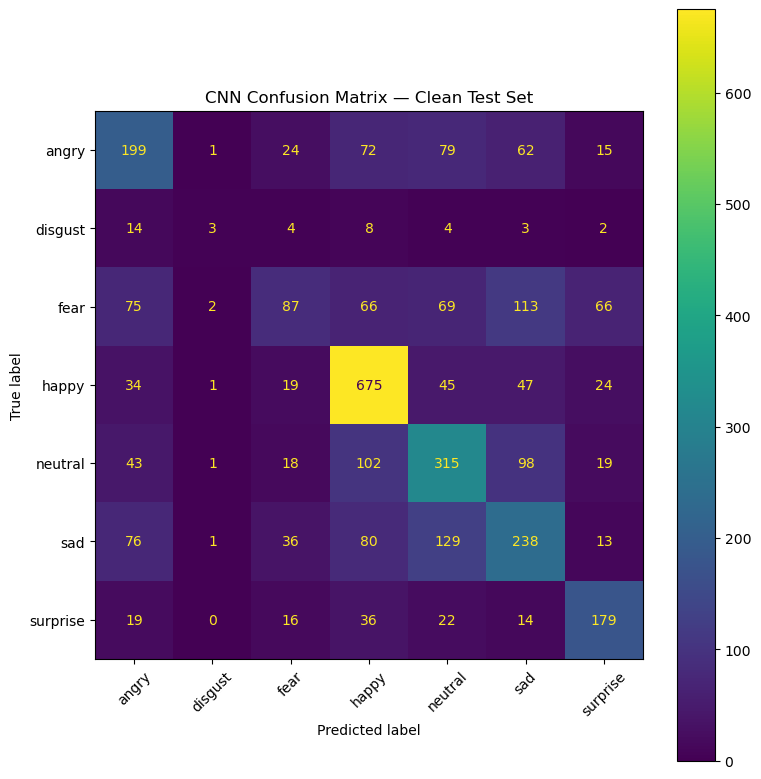

In [80]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_raw.classes
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, xticks_rotation=45)

plt.title("CNN Confusion Matrix — Clean Test Set")
plt.tight_layout()
plt.show()